# CS3 - Field-Scale Screening & Well Ranking (COSTA carbonate wells)

**Petrophys Case Studies - a realistic end-to-end project**

---

**What you will learn**

- How to turn a single-well recipe into a batch loop that survives bad wells and missing parameters.
- How to check cross-well comparability (GR normalization) before ranking.
- How to rank wells on hydrocarbon pore thickness and present tiers with a rationale.
- How to cross-check a hand-built screen against the one-call dynamic workflow.

**Prerequisites.** CS2 (the single-well carbonate recipe used here), lesson 09 (net pay) and
lesson 18 (multiwell studies). The base install is enough.

## 1. The brief

> *"We have logs and core-derived curves over the Kharaib-2 reservoir in all 17 COSTA wells.
> Before we commit capital to a development plan, screen them: rank the wells by
> reservoir quality and hydrocarbon volume, and hand me a short list of the
> best candidates for development - with a defensible rationale."*
> &mdash; Asset manager, subsurface team

This is a **portfolio / screening** problem, not a single-well study. The deliverable is
a **ranked field screening table (17 rows)**, a **cross-well comparison figure set**, and a
**"top candidates for development" recommendation**.

Two things make field screening different from single-well work:

1. **Consistency matters more than depth-by-depth precision.** If we interpret each well
   with a slightly different recipe, the ranking is meaningless. We fix one workflow and
   apply it identically to all 17 wells.
2. **Logs must be made comparable across wells.** Gamma-ray in particular drifts between
   wells (different tool calibration, hole conditions, mud). Before we compare clay content
   well-to-well we check it on a **normalized GR** scale. We show the before/after.

We build on two earlier case studies and *reuse* their recipes rather than re-teach them:

- **CS1** (clastic full formation evaluation) - the general FE chain.
- **CS2** (COSTA carbonate rock typing) - the exact carbonate recipe for a *single* COSTA
  well: limestone-matrix porosity, header Archie parameters, and the critical
  **Rw temperature correction**. CS3 turns that single-well recipe into a batch loop.

### The one correctness step that dominates the whole field: Rw at formation temperature

The Costa LAS headers quote water resistivity `RW` at a reference temperature
`RWT` (~68 degF, i.e. lab/surface). Formation temperature is far higher
(`BHT` ~ 251 degF). Resistivity of brine *falls* as temperature rises, so using the
quoted `RW` directly treats the formation water as far more resistive than it is. With n near 2
that raises **Archie Sw by a factor of about 1.8** (the square root of the roughly 3.3-fold Rw
ratio): in about half of the wells Sw then reads at or above 1.0 almost everywhere, and in the
pay-bearing wells HCPT falls by roughly 10-40%.

We correct `RW` from `RWT` to the formation temperature *at each depth* using the Arps
relation before running Archie:

$$ R_w(T_f) = R_w(T_{ref}) \cdot \frac{T_{ref} + 6.77}{T_f + 6.77} \quad (\text{degF}) $$

Get this wrong once and every well in the ranking is wrong. This is the single most
important line in the batch loop.


In [1]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys as pp

# Physics modules - the same functions CS2 uses
from petrophys.interpretation import porosity as poro
from petrophys.interpretation import saturation as sat
from petrophys.interpretation.temperature import calculate_temperature_profile, arps_equation
import petrophys.evaluation as res_mod
from petrophys.evaluation import summarize_pay
from petrophys.preprocessing.normalization import normalize_log

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 30)

WELLS = pp.list_samples('costa')
COSTA_TOPS = pp.sample('formations_costa')   # labels each file's Kharaib-2 interval
print('petrophys', pp.__version__)
print('COSTA dataset: %d wells' % len(WELLS))
print(WELLS)

petrophys 3.0.0
COSTA dataset: 17 wells
['HW-10', 'HW-24', 'HW-25', 'HW-26', 'HW-27', 'HW-28', 'HW-29', 'HW-3', 'HW-30', 'HW-31', 'HW-32', 'HW-4', 'HW-5', 'HW-6', 'HW-7', 'HW-8', 'HW-9']


## 2. The wells & the data

All 17 COSTA wells are **carbonate**, logged in **feet** at a 0.5 ft step. Each LAS file covers
**only the Kharaib-2 reservoir interval**, not the whole well; the bundled `formations_costa` table
labels that interval in every file. So this is a screen of *one reservoir* across 17 wells. Each
file carries a compact suite:

- **Logs:** `GR`, `RHOB`, `NPHI`, `DT` (sonic), `RT` (deep resistivity).
- **Core-derived curves:** `PHIE_CC` and `PERM_CC` (core-corrected porosity and permeability
  curves) and `SW_INPUT` (a source-provided saturation curve - not a core measurement; see CS2).
- **Header Archie parameters** (via `well.get_parameter`): `RW`, `RWT`, `A`, `M`, `N`, `BHT`.

Let's inventory the wells so we know exactly what we are working with - including any wells
with missing curves or missing header parameters, because those drive our error handling.

In [2]:
inv = []
for wn in WELLS:
    w = pp.read(pp.sample(wn))
    interval = pp.read_formations(COSTA_TOPS, well=w).iloc[0]
    row = {'well': w.name, 'interval': interval['formation_name'], 'samples': w.n_samples,
           'top_ft': round(w.top, 1), 'base_ft': round(w.bottom, 1)}
    # curve presence + how much DT is actually populated (some wells have all-null sonic)
    for m in ['GR', 'RHOB', 'NPHI', 'DT', 'RT', 'PHIE_CC', 'PERM_CC', 'SW_INPUT']:
        row[m] = w.get(m).valid_count() if w.has_curve(m) else 0
    # header Archie params
    for p in ['RW', 'RWT', 'A', 'M', 'N', 'BHT']:
        row[p] = w.get_parameter(p)
    inv.append(row)

inv_df = pd.DataFrame(inv)
print('Interval label(s) from formations_costa:', sorted(set(inv_df['interval'])))
print('Samples per well: %d - %d' % (inv_df['samples'].min(), inv_df['samples'].max()))
print()
print('CURVE VALID-SAMPLE COUNTS (0 = curve absent / all-null):')
print(inv_df[['well', 'samples', 'GR', 'RHOB', 'NPHI', 'DT', 'RT',
              'PHIE_CC', 'PERM_CC', 'SW_INPUT']].to_string(index=False))

Interval label(s) from formations_costa: ['KHARAIB-2']
Samples per well: 337 - 481

CURVE VALID-SAMPLE COUNTS (0 = curve absent / all-null):
 well  samples  GR  RHOB  NPHI  DT  RT  PHIE_CC  PERM_CC  SW_INPUT
HW-10      381 381   381   381   0 381      381      311       160
HW-24      433 433   433   433   0 433      433      389       352
HW-25      413 413   413   413   0 413      413      334       332
HW-26      345 345   345   345   0 345      309      321       230
HW-27      409 409   409   273 409 409      409      335        13
HW-28      407 407   407   407 407 407      407      333        95
HW-29      445 445   445   445   0 445      445      355       393
 HW-3      431 431   431   431 356 431      351      355       321
HW-30      481 481   481   481 481 481      481      470       445
HW-31      421 421   421   421 421 421      421      413         0
HW-32      419 419   419   419 419 419      419      404       343
 HW-4      361 361   361   361   0 361      361      30

In [3]:
print('HEADER ARCHIE PARAMETERS (read live from each LAS):')
print(inv_df[['well', 'RW', 'RWT', 'A', 'M', 'N', 'BHT']].to_string(index=False))
print()
# Flag the data-quality issues that will shape our batch loop
dt_dead = inv_df[inv_df['DT'] == 0]['well'].tolist()
mn_miss = inv_df[inv_df['M'].isna() | inv_df['N'].isna()]['well'].tolist()
print('Wells with dead/absent sonic (DT):', dt_dead if dt_dead else 'none')
print('Wells missing header M and/or N :', mn_miss if mn_miss else 'none')

HEADER ARCHIE PARAMETERS (read live from each LAS):
 well     RW  RWT   A    M    N   BHT
HW-10 0.1373 68.0 1.0 2.03 2.00 251.0
HW-24 0.0760 68.0 1.0 1.97 1.99 251.0
HW-25 0.0778 68.0 1.0 1.97 1.98 251.0
HW-26 0.0702 68.0 1.0 2.01 2.00 251.0
HW-27 0.1000 68.0 1.0  NaN  NaN 251.0
HW-28 0.0760 68.0 1.0 1.95 2.06 251.0
HW-29 0.0847 68.0 1.0 1.94 1.96 251.0
 HW-3 0.0682 68.0 1.0 2.03 2.00 251.0
HW-30 0.0690 68.0 1.0 2.02 2.00 251.0
HW-31 0.1000 68.0 1.0  NaN  NaN 251.0
HW-32 0.0750 68.0 1.0 1.96 1.99 251.0
 HW-4 0.0698 68.0 1.0 2.01 2.03 251.0
 HW-5 0.0850 68.0 1.0 1.91 2.15 251.0
 HW-6 0.0733 68.0 1.0 1.98 2.01 251.0
 HW-7 0.1000 68.0 1.0  NaN  NaN 251.0
 HW-8 0.1000 68.0 1.0  NaN  NaN 251.0
 HW-9 0.1349 68.0 1.0 2.04 1.92 251.0

Wells with dead/absent sonic (DT): ['HW-10', 'HW-24', 'HW-25', 'HW-26', 'HW-29', 'HW-4', 'HW-6', 'HW-7', 'HW-8', 'HW-9']
Wells missing header M and/or N : ['HW-27', 'HW-31', 'HW-7', 'HW-8']


### What the inventory tells us (and how it shapes the loop)

Two data-quality realities emerge, and both must be handled *gracefully* rather than by
crashing or silently dropping a well:

1. **Sonic (`DT`) is unreliable on some wells.** We deliberately build the porosity /
   saturation recipe on **GR / RHOB / NPHI / RT only**, so a dead sonic never breaks a well.
2. **A subset of wells is missing header `M` and `N`** (the Archie cementation and
   saturation exponents). We do **not** drop these wells. Instead we fall back to
   **field-typical carbonate defaults `M = N = 2.0`** and *flag* the well as using defaults,
   so the reader can discount its Sw. Dropping wells from a screening study biases the
   portfolio; flagging them is the honest choice.

Everything else (RW/RWT/A/BHT) is present on every well (see the table above). One pattern to
note: the four wells without header `M`/`N` all carry a round `RW = 0.1000 ohm.m`, while the other
wells quote Rw to three or four significant figures. That looks like a default or placeholder
rather than a measured value, so for those wells *both* Rw and the exponents are uncertain. We keep
the header value (one recipe for every well) and carry the caveat into the ranking.


## 3. Workflow plan

We chain the following steps and apply them **identically** to every well:

| # | Step | Function | Why here |
|---|------|--------|----------|
| 1 | Load LAS + header params | `pp.read`, `well.get_parameter` | one recipe, real params |
| 2 | Porosity (N-D, limestone) | `petrophys.interpretation.porosity.density_porosity`, `total_porosity` | carbonate matrix 2.71, brine 1.1; density porosity in N-D crossover |
| 3 | Temperature profile | `petrophys.interpretation.temperature.calculate_temperature_profile` | need T_f at each depth |
| 4 | **Rw -> formation T** | `petrophys.interpretation.temperature.arps_equation` | *the* correctness step |
| 5 | Archie Sw | `petrophys.interpretation.saturation.archie` | real header m/n (or flagged default) |
| 6 | Vcl from GR | inline linear | net-pay clay cutoff |
| 7 | Net reservoir / net pay | `petrophys.evaluation.summarize_pay` | Costa project cutoffs |
| 8 | Per-well roll-up | the same `summarize_pay` result | avg PHIE, avg Sw, **HC-pore-thickness** |

**Cross-well GR normalization** (Part 4b) sits *beside* this loop: we compute it on the raw
GR of all wells to demonstrate comparability, and confirm our clean/clay GR anchors are
sensible across the wells.

### The screening metric: hydrocarbon pore thickness (HCPT)

Net pay in feet alone is a blunt ranking key - a thick but tight/wet interval can out-rank a
thin, clean, oil-charged one. We rank on **hydrocarbon pore thickness**, a per-well HCPV
index that folds in porosity *and* hydrocarbon saturation over the pay:

$$ \text{HCPT} = \sum_{\text{net pay}} \phi_e \,(1 - S_w)\; \Delta z \quad [\text{ft}] $$

It is the (area-independent) core of any HCPV calculation: multiply by drainage area and divide by the
formation volume factor (Bo) for in-place volume, then multiply by a recovery factor for reserves. For screening, HCPT ranks wells directly
by *how much hydrocarbon-filled pore column each well's Kharaib-2 contains*.

## 4. Execution

### 4a. One recipe, applied to all 17 wells

The function below is the CS2 single-well carbonate recipe wrapped for batch use, with two
robustness additions: (i) missing `M`/`N` fall back to `2.0` and set a flag; (ii) the whole
body is guarded so any unexpected failure is *reported*, not fatal.

The screening roll-up - net reservoir, net pay, the pay averages and HCPT - is one call to
`summarize_pay` (in `petrophys.evaluation`). We pass it the recipe's own VCL, porosity and
Sw arrays. That matters here: every COSTA file carries a core-corrected `PHIE_CC` curve, and a
net-pay calculation that looks curves up by name takes `PHIE_CC` ahead of a `PHIE` we add, so
the pay flags would silently use a different porosity from the HCPT.

The cutoffs are the **Costa project set** - `Vcl < 0.30`, `PHIE > 0.10`, `Sw < 0.60` - and they
are **deliberately tighter** than the library's generic carbonate standard (printed by the cell
below for comparison), because the Kharaib-2 is a high-porosity carbonate and this screen targets
quality rock. CS2 and lesson 18 use the same set, so the three are comparable knob-for-knob.

One porosity detail matters in these wells. Where density porosity exceeds neutron porosity by more
than 0.05 (neutron-density crossover), `total_porosity`'s adaptive rule by default takes the
root-mean-square of the two, the gas-zone approximation of Gaymard and Poupon (1968). The Kharaib-2
is oil-bearing, so the recipe passes `gas_method='density'` and takes density porosity there, the
rule `pp.interpret` applies with its default `hc_type='oil'`. In several wells, HW-3, HW-25 and
HW-30 among them, most samples lie in crossover, so the choice matters for the ranking.

In [4]:
RHOB_MATRIX, RHOB_FLUID = 2.71, 1.10   # calcite matrix, saline brine (~200,000 ppm)
VCL_CLEAN, VCL_CLAY = 8.0, 40.0        # GR gAPI anchors (clean carbonate / clay)
# Costa project cutoffs: deliberately tighter than the generic carbonate
# standard because the Kharaib-2 is a high-porosity carbonate and this
# screening targets quality rock. Same set across CS2 / CS3 / lesson 18.
COSTA_CUTOFFS = dict(vcl_cutoff=0.30, phie_cutoff=0.10, sw_cutoff=0.60)
print('Generic carbonate standard:', res_mod.STANDARD_CUTOFFS['carbonate'])
print('Costa project cutoffs     :', COSTA_CUTOFFS)
VCL_CUT, PHIE_CUT, SW_CUT = (COSTA_CUTOFFS["vcl_cutoff"],
                             COSTA_CUTOFFS["phie_cutoff"],
                             COSTA_CUTOFFS["sw_cutoff"])
DEFAULT_M, DEFAULT_N = 2.0, 2.0        # carbonate fallback when header lacks m/n


def screen_well(well_name):
    """Full carbonate screening recipe for one COSTA well (its Kharaib-2 interval).

    Returns a dict of screening metrics, or a dict with 'error' set on failure.
    Never raises - field screening must survive one bad well.
    """
    try:
        w = pp.read(pp.sample(well_name))

        # --- header params (with graceful m/n fallback) ---
        rw  = w.get_parameter('RW')
        rwt = w.get_parameter('RWT')
        a   = w.get_parameter('A')
        m   = w.get_parameter('M')
        n   = w.get_parameter('N')
        bht = w.get_parameter('BHT')
        flags = []
        if m is None:
            m = DEFAULT_M; flags.append('M=def')
        if n is None:
            n = DEFAULT_N; flags.append('N=def')

        # --- (2) porosity: neutron-density, limestone matrix ---
        rhob = w.get('RHOB').data
        nphi = w.get('NPHI').data
        phid = poro.density_porosity(rhob, RHOB_MATRIX, RHOB_FLUID)
        # Density porosity in neutron-density crossover: the Kharaib-2 is oil-bearing.
        phi  = np.clip(poro.total_porosity(nphi, phid, method='adaptive', gas_method='density'),
                       0.0, 0.45)

        # --- (3-4) temperature profile then Rw -> formation temperature (Arps) ---
        tprof = calculate_temperature_profile(w, bht=bht, surface_temp=rwt)
        tf    = tprof.temperature
        rw_fm = arps_equation(rw, rwt, tf)          # <-- the correctness step

        # --- (5) Archie Sw with formation-temperature Rw ---
        sw = np.clip(sat.archie(w.get('RT').data, rw_fm, phi, a=a, m=m, n=n), 0.0, 1.0)

        # --- (6) Vcl from GR (linear) ---
        gr  = w.get('GR').data
        vcl = np.clip((gr - VCL_CLEAN) / (VCL_CLAY - VCL_CLEAN), 0.0, 1.0)

        # --- (7-8) net reservoir / net pay and the per-well roll-up (Costa cutoffs) ---
        # The recipe's arrays are passed explicitly (see the note above on PHIE_CC).
        pay = summarize_pay(w, vcl=vcl, phie=phi, sw=sw, vcl_cutoff=VCL_CUT,
                            phie_cutoff=PHIE_CUT, sw_cutoff=SW_CUT)
        net_res = pay.net_reservoir
        sw_net_res = float(np.nanmean(sw[net_res])) if net_res.any() else np.nan

        return {
            'well': w.name,
            'gross_ft':   round(pay.gross_thickness, 1),        # thicknesses in ft (well depth unit)
            'net_res_ft': round(pay.net_reservoir_thickness, 1),
            'net_pay_ft': round(pay.net_pay_thickness, 1),
            'avg_PHIE':   round(pay.avg_phie_pay, 3) if pay.n_pay_samples else np.nan,
            'avg_Sw':     round(pay.avg_sw_pay, 3) if pay.n_pay_samples else np.nan,
            'HCPT_ft':    round(pay.hcpt, 2),
            'm_used':     round(m, 2),
            'n_used':     round(n, 2),
            'flags':      ';'.join(flags) if flags else '-',
            'Sw_net_res': round(sw_net_res, 3) if np.isfinite(sw_net_res) else np.nan,
            'error':      None,
        }
    except Exception as exc:                    # safety net: report, do not crash
        return {'well': well_name, 'error': str(exc)[:80]}


# Run all 17 wells
results = [screen_well(wn) for wn in WELLS]
ok      = [r for r in results if r.get('error') is None]
failed  = [r for r in results if r.get('error') is not None]
print()
print('Processed %d/%d wells cleanly.' % (len(ok), len(WELLS)))
if failed:
    print('Wells that FAILED (reported, not dropped):')
    for r in failed:
        print('  %-8s -> %s' % (r['well'], r['error']))
else:
    print('No hard failures - every well produced a screening result.')

Generic carbonate standard: {'vcl_cutoff': 0.3, 'phie_cutoff': 0.045, 'sw_cutoff': 0.7}
Costa project cutoffs     : {'vcl_cutoff': 0.3, 'phie_cutoff': 0.1, 'sw_cutoff': 0.6}



Processed 17/17 wells cleanly.
No hard failures - every well produced a screening result.


Every well produced a result. The wells missing header `M`/`N` were **not** dropped; they
were interpreted with the carbonate default exponents and carry a `flags` marker
(`M=def`/`N=def`) so their Sw can be discounted during ranking.


### 4b. Cross-well GR normalization - and why it matters

Gamma-ray is our clay indicator, and clay volume feeds the **net-rock** cutoff on every
well. But raw GR is not directly comparable well-to-well: tool calibration, borehole size,
mud weight and hole condition all shift the GR scale. If well A reads a clean carbonate at 6
gAPI and well B reads the *same* clean carbonate at 12 gAPI, a fixed clay cutoff penalises
well B for nothing more than a calibration offset.

**Normalization** rescales each well's GR so a chosen low anchor (clean) and high anchor
(clay) line up on a common scale. We use `petrophys.preprocessing.normalization.normalize_log`,
which applies the linear rescale

$$ GR_{norm} = GR_{min} + (GR_{max}-GR_{min})\,\frac{GR-GR_{low}}{GR_{high}-GR_{low}} $$

called as `normalize_log(data, log_min, log_max, log_low, log_high)`. Here we normalize each
well's raw GR to a common **0-150 gAPI** target, anchoring on each well's own P5 (clean) and
P95 (high) percentiles. Treat this as a demonstration of the `normalize_log` mechanics, with two
caveats:

- The check is **circular**: each well's P5 is mapped to 0 by construction, so the "after"
  clean-anchor spread is zero whatever the logs say. The informative number is the *before*
  spread.
- The Kharaib-2 files are almost clean carbonate, so a well's P95 (roughly 20-70 gAPI) is not a
  clay reading. Stretching it to 150 gAPI exaggerates GR (normalized values reach about 250 gAPI)
  and creates an artificial mode near 150. Field practice normalizes each well to a reference
  (key) well's distribution over a common interval (Shier, 2004, *Petrophysics* 45(3)).

In [5]:
TARGET_MIN, TARGET_MAX = 0.0, 150.0     # common GR scale (gAPI)
P_LOW, P_HIGH = 5.0, 95.0               # clean / clay percentile anchors per well

gr_raw  = {}
gr_norm = {}
for wn in WELLS:
    w = pp.read(pp.sample(wn))
    g = w.get('GR').data
    g = g[np.isfinite(g)]
    gr_raw[wn] = g
    low  = np.percentile(g, P_LOW)
    high = np.percentile(g, P_HIGH)
    # normalize_log(data, log_min, log_max, log_low, log_high)
    gr_norm[wn] = normalize_log(g, TARGET_MIN, TARGET_MAX, low, high)

# quantify the spread of the "clean carbonate" reading BEFORE vs AFTER
clean_before = np.array([np.percentile(gr_raw[wn], P_LOW) for wn in WELLS])
clean_after  = np.array([np.percentile(gr_norm[wn], P_LOW) for wn in WELLS])
print('Clean-carbonate GR anchor (P%d) spread across the 17 wells:' % P_LOW)
print('  BEFORE normalization : %.1f - %.1f gAPI  (range %.1f)'
      % (clean_before.min(), clean_before.max(), np.ptp(clean_before)))
print('  AFTER  normalization : %.1f - %.1f gAPI  (range %.1f - zero by construction, P5 -> 0)'
      % (round(clean_after.min(), 6) + 0.0, round(clean_after.max(), 6) + 0.0, np.ptp(clean_after)))   # +0.0 avoids printing -0.0
print('BEFORE spread as a share of the fixed 8-40 gAPI Vcl window used in the screen: %.0f%%'
      % (100.0 * np.ptp(clean_before) / (40.0 - 8.0)))
print('Largest normalized GR: %.0f gAPI (each well\'s P95 is stretched to 150)'
      % max(np.max(gr_norm[wn]) for wn in WELLS))

Clean-carbonate GR anchor (P5) spread across the 17 wells:
  BEFORE normalization : 5.1 - 13.6 gAPI  (range 8.4)
  AFTER  normalization : 0.0 - 0.0 gAPI  (range 0.0 - zero by construction, P5 -> 0)
BEFORE spread as a share of the fixed 8-40 gAPI Vcl window used in the screen: 26%
Largest normalized GR: 259 gAPI (each well's P95 is stretched to 150)


#### What the normalization check does and does not show

The *before* spread is the real finding: the clean-carbonate GR baseline differs by several gAPI
between wells (printed above), a noticeable share of the fixed 8-40 gAPI window the screen uses for
Vcl. The *after* spread is zero only because the method maps every well's P5 to 0, so it proves
nothing about comparability. A non-circular check would normalize to a key well and compare
distributions over a common interval.

**Figure 1 - GR distributions before vs after normalization.** Each panel pools all 17
wells' GR readings into one histogram; the 17 per-well clean-carbonate anchors (each well's P5) are
drawn as vertical lines. Before, the anchors are staggered across the spread printed above; after,
they all sit at 0 by construction. The bump near 150 gAPI in the right panel is created by
stretching each well's P95 to 150, not by clay.

The companion **Figure 1b** uses a *different* normalization: `create_multiwell_overlay(normalize=True)`
robustly min-max scales each well's GR to a unitless 0-1 range (values above 1 are beyond the upper
anchor). The wells cover different depth windows (about 8230-8830 ft), so the plot compares the
shape of each GR profile, not a depth correlation.

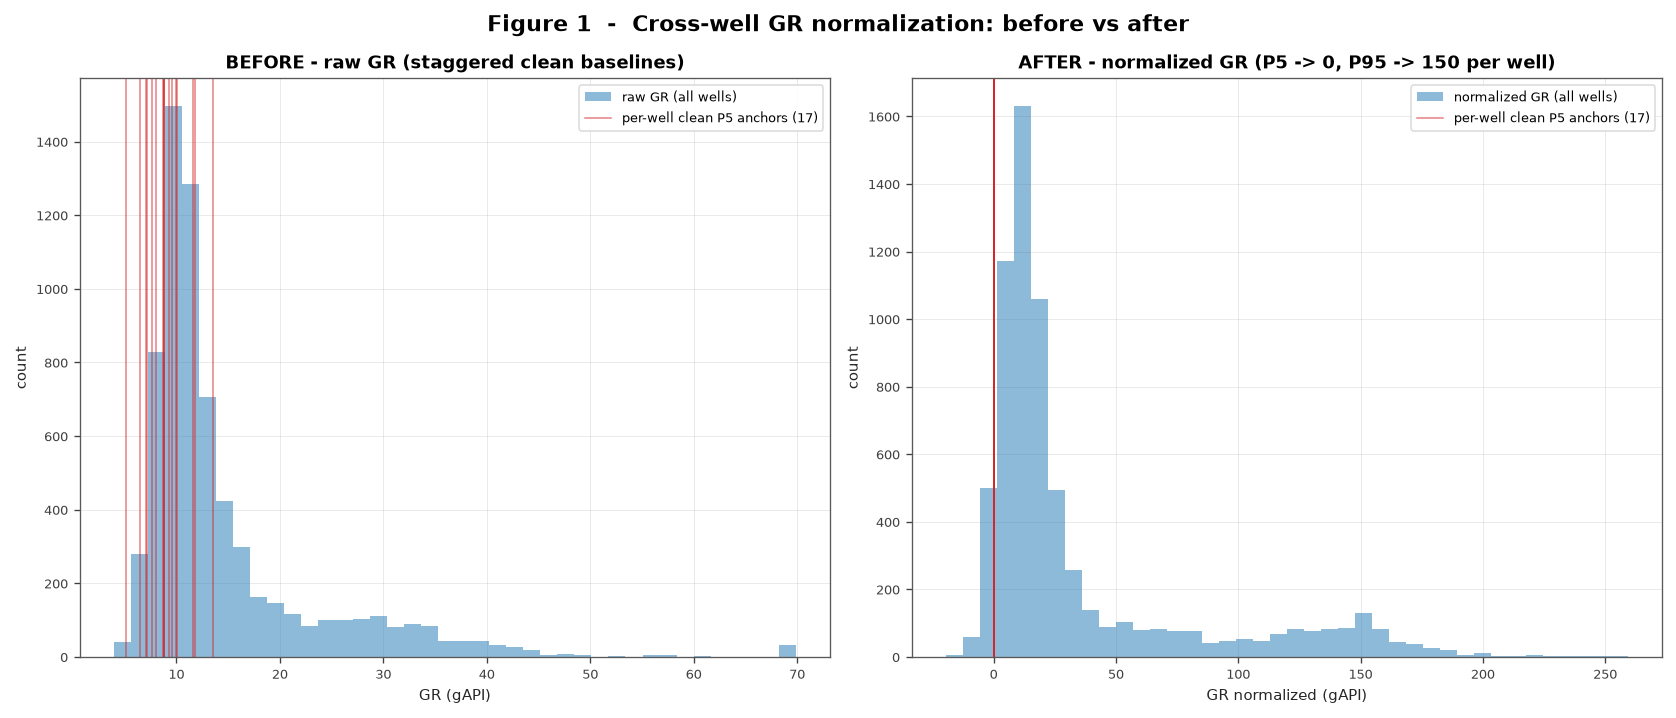

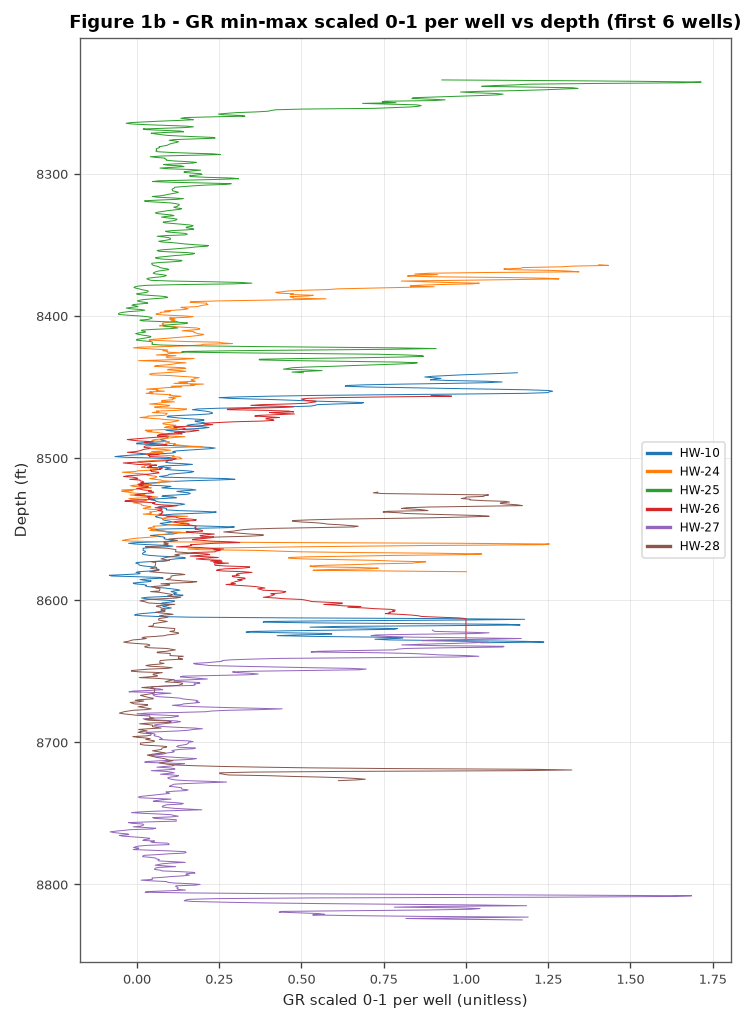

In [6]:
from petrophys.visualization import create_histogram_comparison, create_multiwell_overlay

# Figure 1: cross-well GR distributions before vs after normalization, rendered by
# the library histogram-comparison helper. We pool every well's clean-carbonate GR
# reading (its P5 anchor) so the panels show how the field-wide clean baseline
# collapses onto a single value after normalization.
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# (a) raw GR pooled across all wells; the per-well clean anchors as vertical lines
create_histogram_comparison(
    {'raw GR (all wells)': np.concatenate([gr_raw[wn] for wn in WELLS])},
    bins=40, ax=axes[0], xlabel='GR (gAPI)',
    title='BEFORE - raw GR (staggered clean baselines)',
)
# (b) normalized GR pooled across all wells; anchors at 0 by construction
create_histogram_comparison(
    {'normalized GR (all wells)': np.concatenate([gr_norm[wn] for wn in WELLS])},
    bins=40, ax=axes[1], xlabel='GR normalized (gAPI)',
    title='AFTER - normalized GR (P5 -> 0, P95 -> 150 per well)',
)
for ax, anchors in ((axes[0], clean_before), (axes[1], clean_after)):
    for i, x in enumerate(anchors):
        ax.axvline(x, color='tab:red', lw=0.9, alpha=0.6,
                   label='per-well clean P5 anchors (17)' if i == 0 else None)
    ax.legend(loc='upper right', fontsize=8)

fig.suptitle('Figure 1  -  Cross-well GR normalization: before vs after', fontsize=13)
plt.tight_layout()
plt.show()

# Companion view: GR vs depth for a handful of wells via the library multi-well
# overlay. normalize=True robustly min-max scales each well's curve to 0-1 - a
# different normalization from the 0-150 gAPI one above.
overlay_wells = [pp.read(pp.sample(wn)) for wn in WELLS[:6]]
create_multiwell_overlay(overlay_wells, 'GR', normalize=True,
                         title='Figure 1b - GR min-max scaled 0-1 per well vs depth (first 6 wells)')
plt.gca().set_ylabel('Depth (ft)')
plt.gca().set_xlabel('GR scaled 0-1 per well (unitless)')
plt.show()

## 5. Integrated result - the field screening table

We assemble the per-well metrics into a single table and **sort by HCPT** (hydrocarbon pore
thickness) - the ranking key from Part 3. HCPT counts hydrocarbon-filled pore volume; it does
not say how much of it is movable.


In [7]:
screen = pd.DataFrame(ok)
screen = screen[['well', 'gross_ft', 'net_res_ft', 'net_pay_ft',
                 'avg_PHIE', 'avg_Sw', 'HCPT_ft', 'm_used', 'n_used', 'flags']]
screen = screen.sort_values('HCPT_ft', ascending=False).reset_index(drop=True)
screen.insert(0, 'rank', np.arange(1, len(screen) + 1))

print('=== COSTA KHARAIB-2 SCREENING TABLE (17 wells, ranked by HCPT) ===')
print(screen.to_string(index=False))

print()
print('Totals across the 17 wells:')
print('  Total net pay (all wells) : %.0f ft' % screen['net_pay_ft'].sum())
print('  Total HCPT (all wells)    : %.0f ft' % screen['HCPT_ft'].sum())
print('  Wells with net pay > 0    : %d / %d'
      % ((screen['net_pay_ft'] > 0).sum(), len(screen)))
print('  Wells on default m/n      : %d (Sw less certain)'
      % (screen['flags'] != '-').sum())

=== COSTA KHARAIB-2 SCREENING TABLE (17 wells, ranked by HCPT) ===
 rank  well  gross_ft  net_res_ft  net_pay_ft  avg_PHIE  avg_Sw  HCPT_ft  m_used  n_used       flags
    1 HW-30     240.5       204.0       202.0     0.331   0.134    58.52    2.02    2.00           -
    2 HW-29     222.5       182.0       182.0     0.302   0.090    50.14    1.94    1.96           -
    3 HW-25     206.5       153.5       153.0     0.270   0.094    37.77    1.97    1.98           -
    4  HW-3     215.5       166.5       166.5     0.226   0.132    32.80    2.03    2.00           -
    5 HW-24     216.5       164.0       149.0     0.254   0.249    28.42    1.97    1.99           -
    6  HW-6     208.5       142.0       139.0     0.254   0.253    26.64    1.98    2.01           -
    7 HW-32     209.5       170.0       103.0     0.317   0.298    23.19    1.96    1.99           -
    8 HW-26     172.5        48.0        38.5     0.161   0.425     3.55    2.01    2.00           -
    9 HW-10     190.5   

**Figure 2 - ranked bar chart: net pay and HCPT per well.** Wells sorted by HCPT.
Net pay (ft) and HCPT (ft) are plotted side by side so we can see where thick pay does *not*
translate into hydrocarbon volume (tight or high-Sw pay).

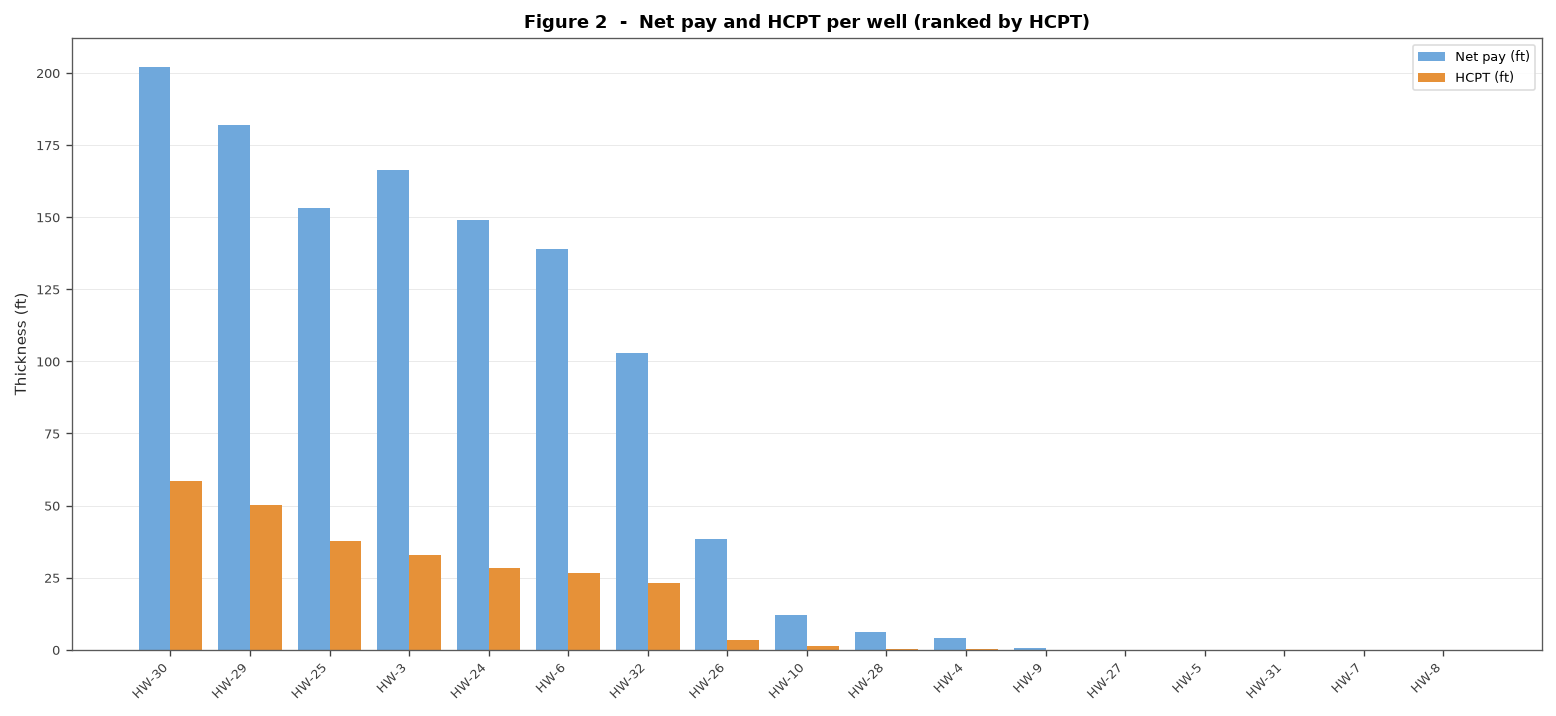

In [8]:
from petrophys.visualization import create_bar_comparison

# Figure 2: net pay and HCPT per well as grouped bars via the library bar helper.
# The table is already sorted by HCPT, so we plot in that order (no re-sort).
order = screen['well'].tolist()
fig, ax = create_bar_comparison(
    order,
    {'Net pay (ft)': screen['net_pay_ft'].values,
     'HCPT (ft)':    screen['HCPT_ft'].values},
    colors=['#6fa8dc', '#e69138'],
    figsize=(13, 6),
    ylabel='Thickness (ft)',
    title='Figure 2  -  Net pay and HCPT per well (ranked by HCPT)',
)
plt.tight_layout()
plt.show()

**Figure 3 - reservoir-quality scatter: average porosity vs average Sw over the pay,
coloured by HCPT (viridis colourbar).** The porosity here (column `avg_PHIE`) is the N-D total
porosity of the recipe; in these clean carbonates (GR mostly below 20 gAPI) it is close to
effective porosity, but it is not shale-corrected. With PHIE on the x-axis and Sw on the y-axis, the
best wells plot toward the **lower-right** - high porosity, low Sw - and that is where the
top-ranked wells sit, in the brightest HCPT colours. Only pay-bearing wells appear: wells with
no pay have no pay-averaged PHIE/Sw and are dropped from this plot.

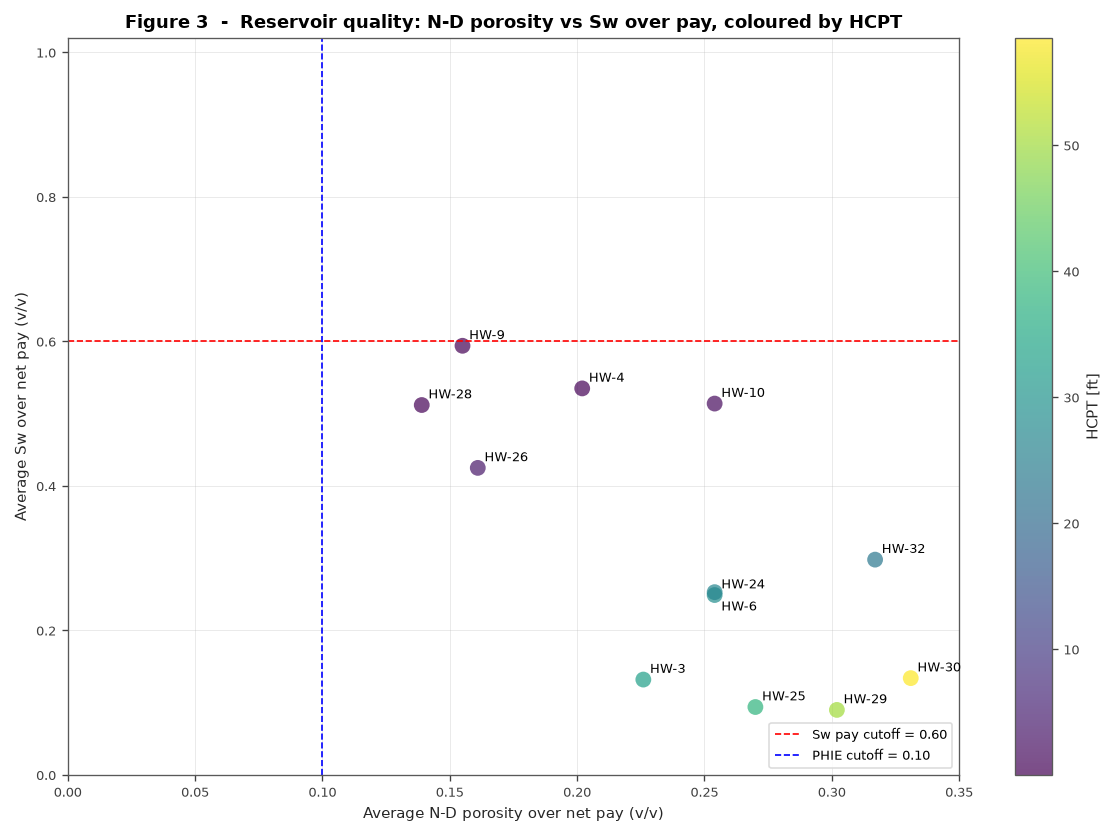

In [9]:
from petrophys.model.well import Well
from petrophys.visualization import create_crossplot

# Figure 3: reservoir-quality crossplot - average porosity vs average Sw over the
# pay, coloured by HCPT. The per-well averages are attached to a small helper Well
# (one sample per pay-bearing well) so the library crossplot can render them.
sub = screen.dropna(subset=['avg_PHIE', 'avg_Sw']).copy()

field = Well('COSTA Kharaib-2 screening')
field.depth = np.arange(len(sub), dtype=float)
field.add_curve('AVG_PHIE', sub['avg_PHIE'].values, unit='v/v')
field.add_curve('AVG_SW',   sub['avg_Sw'].values,   unit='v/v')
field.add_curve('HCPT',     sub['HCPT_ft'].values,  unit='ft')

cp = create_crossplot(
    field, 'AVG_PHIE', 'AVG_SW', color_curve='HCPT',
    xlim=(0, 0.35), ylim=(0, 1.02), cmap='viridis', marker_size=90,
    figsize=(10, 7),
    title='Figure 3  -  Reservoir quality: N-D porosity vs Sw over pay, coloured by HCPT',
)
# annotate each well and add the cutoff reference lines on the returned axis
LABEL_OFFSET = {'HW-6': (4, -11)}    # HW-6 and HW-24 plot almost on top of each other
for _, r in sub.iterrows():
    cp.ax.annotate(r['well'], (r['avg_PHIE'], r['avg_Sw']),
                   xytext=LABEL_OFFSET.get(r['well'], (4, 4)), textcoords='offset points', fontsize=8)
cp.ax.axhline(SW_CUT, color='r', ls='--', lw=1, label='Sw pay cutoff = %.2f' % SW_CUT)
cp.ax.axvline(PHIE_CUT, color='b', ls='--', lw=1, label='PHIE cutoff = %.2f' % PHIE_CUT)
cp.ax.set_xlabel('Average N-D porosity over net pay (v/v)')
cp.ax.set_ylabel('Average Sw over net pay (v/v)')
cp.ax.legend(loc='lower right', fontsize=8)
cp.show()

**Figure 4 - the two top-ranked wells, side by side.** A quick visual sanity check on
the winners: GR, porosity (the recipe's N-D porosity, stored as `PHIE`), Sw and the net-pay flag
for the #1 and #2 wells. Good
candidates show clean GR, high porosity and a thick low-Sw (gold) pay column.

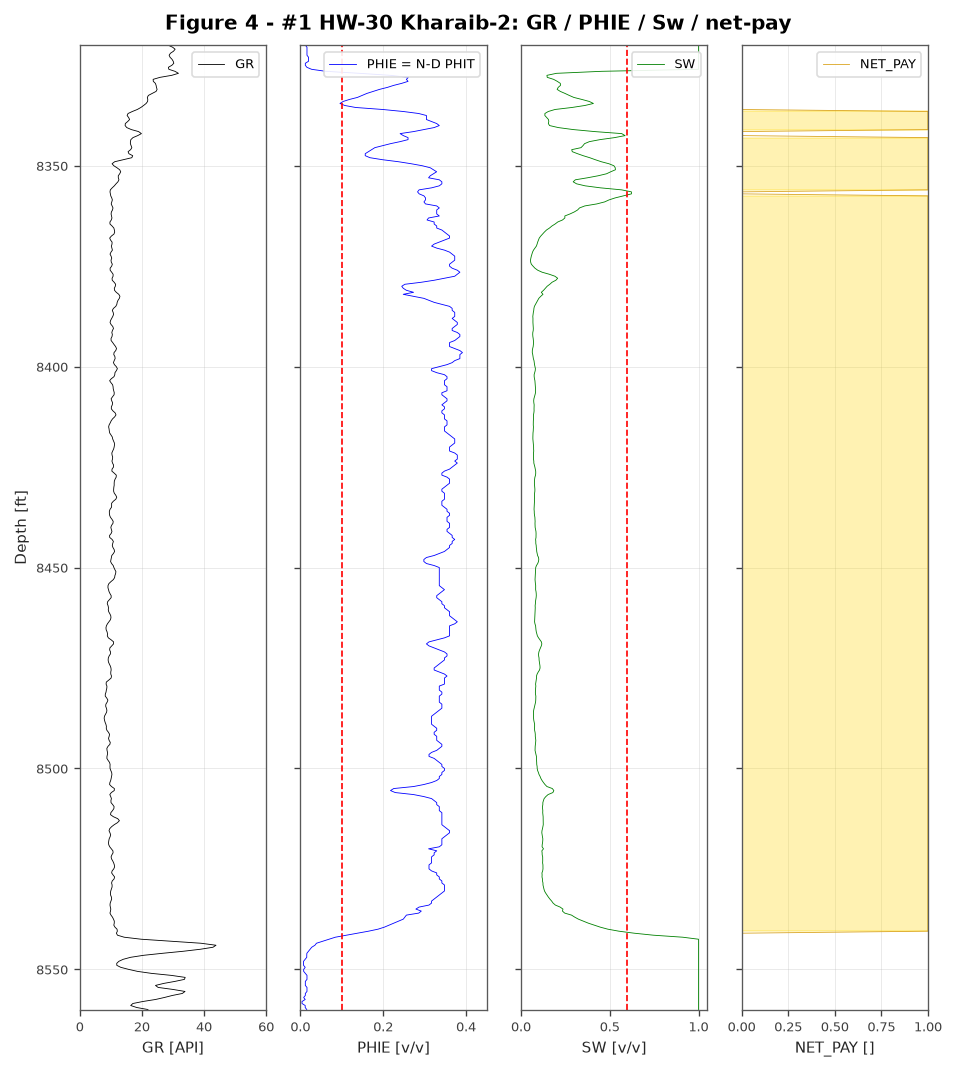

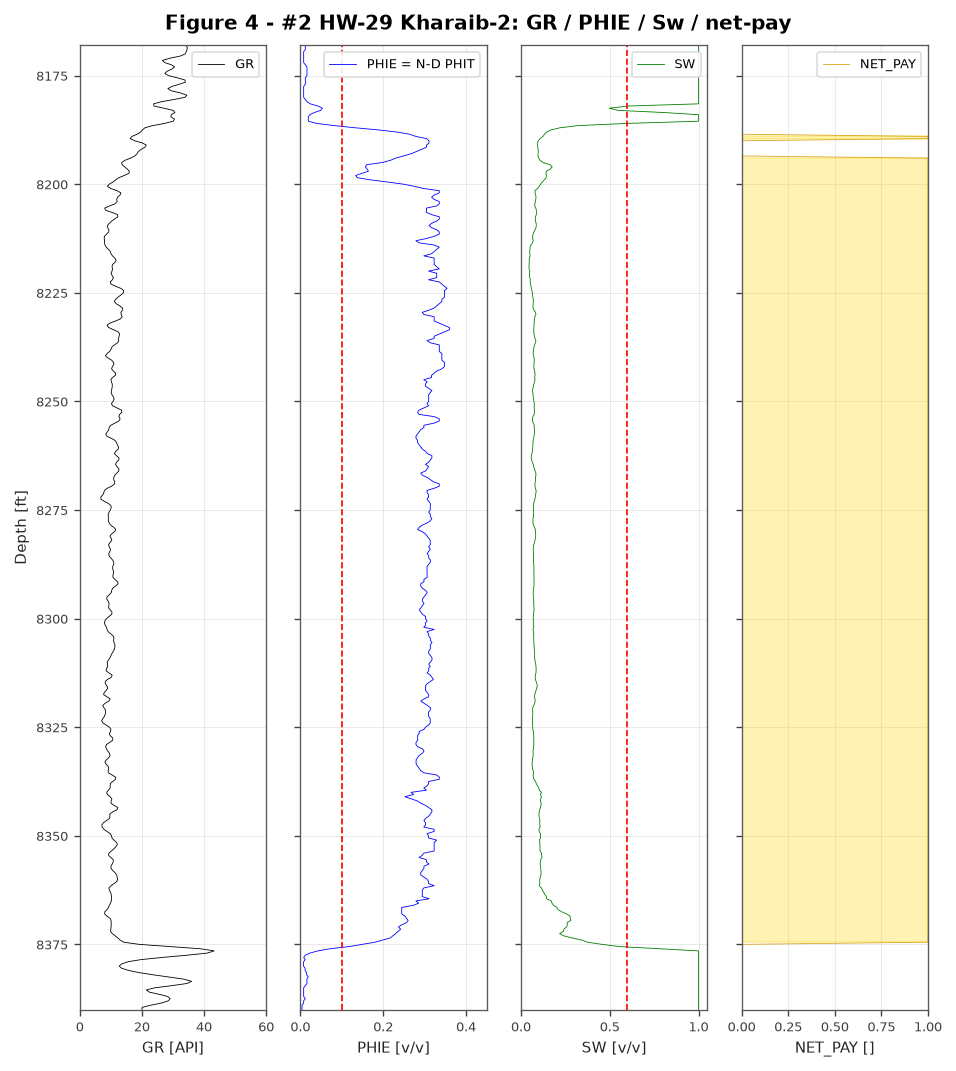

In [10]:
from petrophys.visualization import LogPlot


def quick_panel(well_name, title):
    """Compute the screening curves for one well, attach them, and render a
    4-track GR / PHIE / Sw / net-pay panel with the library LogPlot."""
    w = pp.read(pp.sample(well_name))
    rw_ = w.get_parameter('RW'); rwt_ = w.get_parameter('RWT')
    a_ = w.get_parameter('A')
    m_ = w.get_parameter('M') or DEFAULT_M
    n_ = w.get_parameter('N') or DEFAULT_N
    bht_ = w.get_parameter('BHT')
    rhob = w.get('RHOB').data; nphi = w.get('NPHI').data
    phi = np.clip(poro.total_porosity(nphi, poro.density_porosity(rhob, RHOB_MATRIX, RHOB_FLUID),
                                      method='adaptive', gas_method='density'), 0, 0.45)
    tf = calculate_temperature_profile(w, bht=bht_, surface_temp=rwt_).temperature
    sw = np.clip(sat.archie(w.get('RT').data, arps_equation(rw_, rwt_, tf), phi,
                            a=a_, m=m_, n=n_), 0, 1)
    gr = w.get('GR').data
    vcl = np.clip((gr - VCL_CLEAN) / (VCL_CLAY - VCL_CLEAN), 0, 1)
    w.add_curve('VCL', vcl); w.add_curve('PHIE', phi, unit='v/v'); w.add_curve('SW', sw, unit='v/v')
    pay = summarize_pay(w, vcl=vcl, phie=phi, sw=sw, vcl_cutoff=VCL_CUT,
                        phie_cutoff=PHIE_CUT, sw_cutoff=SW_CUT)     # same flags as the table
    w.add_curve('NET_PAY', pay.net_pay.astype(float), unit='')

    lp = LogPlot(w, figsize=(8, 9))
    lp.create_figure(n_tracks=4)
    lp.add_curve(0, 'GR', color='black', xlim=(0, 60))
    lp.add_curve(1, 'PHIE', color='blue', xlim=(0, 0.45), label='PHIE = N-D PHIT')   # recipe clips at 0.45
    lp.axes[1].axvline(PHIE_CUT, color='r', ls='--', lw=1)
    lp.add_curve(2, 'SW', color='green', xlim=(0, 1.05))
    lp.axes[2].axvline(SW_CUT, color='r', ls='--', lw=1)
    lp.add_curve(3, 'NET_PAY', color='goldenrod', xlim=(0, 1))
    lp.add_fill(3, 'NET_PAY', 0.0, color='gold', where='right')
    lp.set_depth_range()
    lp.add_title(title)
    lp.show()


# Figure 4: quick QC panels for the two top-ranked wells.
top2 = screen['well'].iloc[:2].tolist()
quick_panel(top2[0], 'Figure 4 - #1 %s Kharaib-2: GR / PHIE / Sw / net-pay' % top2[0])
quick_panel(top2[1], 'Figure 4 - #2 %s Kharaib-2: GR / PHIE / Sw / net-pay' % top2[1])

## 6. Interpretation & deliverable

### The ranking

The wells split cleanly into three tiers on HCPT (the thresholds are in the next cell):

- **Tier 1 - development candidates (high HCPT):** the top wells combine thick net pay,
  high porosity and low-to-moderate Sw over the pay. These are the sweet spots.
- **Tier 2 - contingent / step-out:** moderate HCPT - real pay but either thinner,
  lower-porosity, or higher-Sw. Worth appraising, not the first dollar.
- **Tier 3 - wet (HCPT ~ 0):** wells that carry substantial net reservoir - their porosity
  clears the cutoff - but whose Archie Sw over that net reservoir is high (printed below), so
  little or none of it passes the Sw cutoff. Not development targets on today's data. Four of
  them (HW-7, HW-8, HW-27, HW-31) rest on defaulted `m = n = 2` *and* a round header
  `RW = 0.1000 ohm.m`, so their wet call is the least certain in the table.

In [11]:
top3 = screen.head(3)
print('=== TOP 3 CANDIDATES FOR DEVELOPMENT ===')
print(top3[['rank', 'well', 'net_pay_ft', 'avg_PHIE', 'avg_Sw', 'HCPT_ft', 'flags']]
      .to_string(index=False))
print()
share = 100.0 * top3['HCPT_ft'].sum() / screen['HCPT_ft'].sum()
print('These 3 wells carry %.0f%% of the total HCPT of the 17 wells.' % share)
print()
TIER1_MIN, TIER2_MIN = 20.0, 1.0        # HCPT thresholds (ft)
print('Tier breakdown (by HCPT):')
t1 = screen[screen['HCPT_ft'] >= TIER1_MIN]
t2 = screen[(screen['HCPT_ft'] < TIER1_MIN) & (screen['HCPT_ft'] >= TIER2_MIN)]
t3 = screen[screen['HCPT_ft'] < TIER2_MIN]
print('  Tier 1 (HCPT >= %.0f ft): %2d wells -> %s' % (TIER1_MIN, len(t1), ', '.join(t1['well'])))
print('  Tier 2 (%.0f-%.0f ft)      : %2d wells -> %s' % (TIER2_MIN, TIER1_MIN, len(t2), ', '.join(t2['well'])))
print('  Tier 3 (< %.0f ft, wet)  : %2d wells -> %s' % (TIER2_MIN, len(t3), ', '.join(t3['well'])))
print()
print('Tier 3 detail - net reservoir, net pay and mean Archie Sw over the net reservoir:')
detail = pd.DataFrame(ok).set_index('well').loc[t3['well'], ['net_res_ft', 'net_pay_ft', 'Sw_net_res']]
print(detail.to_string())

=== TOP 3 CANDIDATES FOR DEVELOPMENT ===
 rank  well  net_pay_ft  avg_PHIE  avg_Sw  HCPT_ft flags
    1 HW-30       202.0     0.331   0.134    58.52     -
    2 HW-29       182.0     0.302   0.090    50.14     -
    3 HW-25       153.0     0.270   0.094    37.77     -

These 3 wells carry 56% of the total HCPT of the 17 wells.

Tier breakdown (by HCPT):
  Tier 1 (HCPT >= 20 ft):  7 wells -> HW-30, HW-29, HW-25, HW-3, HW-24, HW-6, HW-32
  Tier 2 (1-20 ft)      :  2 wells -> HW-26, HW-10
  Tier 3 (< 1 ft, wet)  :  8 wells -> HW-28, HW-4, HW-9, HW-27, HW-5, HW-31, HW-7, HW-8

Tier 3 detail - net reservoir, net pay and mean Archie Sw over the net reservoir:
       net_res_ft  net_pay_ft  Sw_net_res
well                                     
HW-28       162.5         6.0       0.971
HW-4        133.5         4.0       0.934
HW-9        153.0         0.5       0.987
HW-27       158.0         0.0       0.994
HW-5         57.5         0.0       0.967
HW-31       164.5         0.0       1.000
HW

### Recommendation (the deliverable)

**Prioritise the Tier-1 wells for development.** They dominate the hydrocarbon pore
volume of the 17 wells, and their quality is driven by genuine rock properties (high porosity)
*and* charge (low Sw), not by a single favourable input. Concretely:

1. **Rank #1-#3** are the primary development candidates and carry a large share of the total
   HCPT between them (printed above). Advance to volumetric/reserves work: multiply each well's
   HCPT by its drainage area and divide by the formation volume factor (Bo) for in-place volume,
   then multiply by a recovery factor for reserves.
2. **Tier 2** wells are appraisal / infill candidates: real pay, lower priority. Re-rank
   them once dynamic (pressure/production) data narrows the Sw uncertainty.
3. **Tier 3** wells are wet in the Kharaib-2 on this interpretation. Before writing them off,
   confirm Rw and m/n for the four wells on defaulted values (round `RW = 0.1000`, `M=def`/`N=def`)
   and confirm the FWL - and remember that each LAS file covers only the Kharaib-2, so other zones
   in these wells were never screened here. They are not first-phase targets.
4. **Discount any candidate flagged `M=def`/`N=def`.** Their Sw rests on assumed exponents;
   acquire or model m/n before booking volumes on them.

A note on the GR normalization (Part 4b): the ranking loop itself uses each well's **raw** GR
with fixed 8/40 gAPI Vcl anchors - the normalized GR is never fed into any ranked quantity.
Normalization ran alongside the screen as a QC check. The per-well clean anchors spread by the
amount printed in Part 4b - about a quarter of the 8-40 gAPI Vcl window - so the fixed anchors
shift Vcl between wells. With a Vcl cutoff of 0.30 and these mostly clean carbonates the effect on
pay is limited, but it is not zero; exercise 1 tests it. A production screening should normalize to
a key well and feed the result into the Vcl step.

## 7. Limitations & assumptions

Screening is deliberately fast and uniform, which means honest caveats:

- **One reservoir only.** Every file is the Kharaib-2 interval; the ranking says nothing about
  other zones in these wells.
- **Volumetric, not economic.** HCPT is a *per-well column* index (ft). It is **not** OOIP:
  it omits drainage area, formation-volume factor, and recovery efficiency. It ranks wells;
  it does not book barrels.
- **One recipe for 17 wells.** We applied a single carbonate matrix (calcite, 2.71 g/cc),
  one N-D porosity method, and one cutoff set to every well. Individual wells may warrant
  local matrix or cutoff tuning; that would change absolute numbers and could reorder wells with similar HCPT.
- **Assumed Archie exponents on some wells.** Wells flagged `M=def`/`N=def` use carbonate
  defaults `m = n = 2.0`, and the same four wells carry a round header `RW = 0.1000 ohm.m` that
  looks like a default. Their Sw - and therefore their HCPT and Tier-3 call - carries extra
  uncertainty.
- **Porosity is N-D total porosity.** The recipe's `PHIE` is not shale-corrected; that is
  acceptable in these clean carbonates but not in a shaly interval.
- **Header Rw is fresher than the brine.** The header `RW` values (0.068-0.137 ohm.m at 68 degF)
  correspond to roughly 50,000-125,000 ppm NaCl, fresher than the ~200,000 ppm brine assumed for
  porosity. Where the true water is saltier, Archie Sw is too high and HCPT too low.
- **Rw temperature correction depends on BHT.** We trust the header `BHT` and a
  surface-to-BHT gradient. A wrong BHT tilts Sw the same way on every well (a systematic, not
  random, error).
- **No independent FWL per well.** We screen on log Sw against fixed cutoffs; we did not fit a
  saturation-height / free-water-level model per well (that was CS2's job on a single well).
  Tier-3 "wet" calls should be confirmed against pressure/FWL data.
- **No borehole-quality mask.** COSTA wells have no caliper, so we could not exclude washed-out
  intervals; badly enlarged hole would inflate porosity and pay locally.

## 8. Appendix - reproduce & extend

**Re-run the whole screen** on any subset of COSTA wells - the `screen_well` recipe is
self-contained:

```python
subset = ['HW-30', 'HW-29', 'HW-25']
df = pd.DataFrame([screen_well(wn) for wn in subset])
df.sort_values('HCPT_ft', ascending=False)
```

**Apply to another set of wells:** point `screen_well` at a different sample set from
`pp.list_samples(...)`. For clastics, use the clastic cutoffs
(`res_mod.STANDARD_CUTOFFS['clastic']`) in `summarize_pay`, set `RHOB_MATRIX = 2.65`
(quartz), and use clastic GR anchors.

**Tighten the screen:** to convert HCPT into real volumes, multiply each well's `HCPT_ft` by
its drainage area (`acres * 43560` ft^2) and divide by the oil FVF - the summation module
(`petrophys.evaluation.summaries.calculate_hcpv` / `calculate_ooip`) does this properly once you have
areas.

The cell below re-emits the final ranked screening table as the portfolio deliverable.

In [12]:
print('COSTA KHARAIB-2 - FINAL SCREENING DELIVERABLE (ranked by HCPT)')
print('=' * 78)
print(screen.to_string(index=False))
print()
print('Top-3 development candidates:', ', '.join(screen['well'].head(3)))

COSTA KHARAIB-2 - FINAL SCREENING DELIVERABLE (ranked by HCPT)
 rank  well  gross_ft  net_res_ft  net_pay_ft  avg_PHIE  avg_Sw  HCPT_ft  m_used  n_used       flags
    1 HW-30     240.5       204.0       202.0     0.331   0.134    58.52    2.02    2.00           -
    2 HW-29     222.5       182.0       182.0     0.302   0.090    50.14    1.94    1.96           -
    3 HW-25     206.5       153.5       153.0     0.270   0.094    37.77    1.97    1.98           -
    4  HW-3     215.5       166.5       166.5     0.226   0.132    32.80    2.03    2.00           -
    5 HW-24     216.5       164.0       149.0     0.254   0.249    28.42    1.97    1.99           -
    6  HW-6     208.5       142.0       139.0     0.254   0.253    26.64    1.98    2.01           -
    7 HW-32     209.5       170.0       103.0     0.317   0.298    23.19    1.96    1.99           -
    8 HW-26     172.5        48.0        38.5     0.161   0.425     3.55    2.01    2.00           -
    9 HW-10     190.5       

### Cross-check against the dynamic workflow (lesson 18)

Lesson 18 batch-runs these wells through the **dynamic workflow** - the engine behind
`pp.interpret` - with the same Costa project cutoffs. The cutoffs are identical, but the *recipe*
is not: this screen uses the header Archie constants with an Arps-corrected Rw and a fixed
limestone density-neutron porosity, while the workflow resolves the matrix from the data, runs
its own Sw chain, and takes porosity for saturation, BVW and net pay from each file's supplied
core-corrected `PHIE_CC` (its own PHIE fills any sample where `PHIE_CC` is missing). The cell below runs `pp.interpret` on every well and compares net
pay, so the size of that recipe difference is computed rather than quoted.

In the carbonate domain the workflow routes saturation sample by sample: Archie in clean rock; shaly
samples get Dual Water only with a supplied bound-water resistivity `rwb` (it is never estimated),
otherwise the clastic shaly-sand routing - Indonesia here, where no salinity, CEC or `rwb` is given.
Its calcite-dolomite solve uses the generic carbonate calibration by default;
`carbonate_calibration="costa"` applies the COSTA field calibration instead: illite from GR, and a
1.1 g/cm3 brine for porosity and the mineral volumes alike, unless `rho_fl` is set.

In [13]:
rows = []
for wn in WELLS:
    # The COSTA wells are carbonates; the lithology domain defaults to clastic.
    wf = pp.interpret(pp.read(pp.sample(wn)), lithology="carbonate", **COSTA_CUTOFFS)
    rows.append({'well': wn, 'workflow_net_pay_ft': wf.summary()['net_thickness']['net_pay']})
check = screen[['well', 'rank', 'net_pay_ft']].merge(pd.DataFrame(rows), on='well')
check['diff_ft'] = (check['workflow_net_pay_ft'] - check['net_pay_ft']).round(1)
print(check.to_string(index=False))

thick = check[check['net_pay_ft'] >= 50]
rel = (thick['diff_ft'].abs() / thick['net_pay_ft']).max()
top3 = {src: check.sort_values(col, ascending=False)['well'].head(3).tolist()
        for src, col in (('screen', 'net_pay_ft'), ('workflow', 'workflow_net_pay_ft'))}
print()
print('Largest relative difference where the screen books >= 50 ft: %.0f%%' % (100 * rel))
print('Top 3 by net pay - screen   :', top3['screen'])
print('Top 3 by net pay - workflow :', top3['workflow'])

 well  rank  net_pay_ft  workflow_net_pay_ft  diff_ft
HW-30     1       202.0                206.0      4.0
HW-29     2       182.0                188.5      6.5
HW-25     3       153.0                155.0      2.0
 HW-3     4       166.5                189.5     23.0
HW-24     5       149.0                148.5     -0.5
 HW-6     6       139.0                141.5      2.5
HW-32     7       103.0                105.0      2.0
HW-26     8        38.5                 39.5      1.0
HW-10     9        12.0                 10.5     -1.5
HW-28    10         6.0                  4.0     -2.0
 HW-4    11         4.0                  0.0     -4.0
 HW-9    12         0.5                  0.0     -0.5
HW-27    13         0.0                  0.5      0.5
 HW-5    14         0.0                  0.0      0.0
HW-31    15         0.0                  0.0      0.0
 HW-7    16         0.0                  0.0      0.0
 HW-8    17         0.0                  0.5      0.5

Largest relative difference

Two defensible recipes, one documented difference: where the screen books thick pay, the two
agree to within the printed percentage and pick the same three leading wells by net pay, though not
in the same order: HW-3 carries the largest thick-pay difference and moves to second place in the
workflow's net-pay order. The relative difference is largest for the thin, wet wells, where a few
feet either way changes the percentage a lot. (The HCPT ranking in Part 5 can differ from a net-pay ranking - that is the point of using
HCPT.)

### Recap

- We turned a single-well carbonate recipe (CS2) into a **17-well batch screen** of the Kharaib-2
  interval with one uniform workflow and graceful handling of missing curves/parameters.
- The **Rw -> formation-temperature** Arps correction is the dominant correctness step; skip
  it and Archie Sw rises by a factor of about 1.8, to 1 or more almost everywhere in about half of
  the wells.
- **GR normalization** ran alongside the ranking as a QC check. Its useful output is the
  *before* spread of the clean anchors (several gAPI); the zero *after* spread holds by
  construction. The ranking itself uses raw GR with fixed 8/40 gAPI anchors; a production screen
  should normalize to a key well and feed the result into the Vcl step.
- We ranked the wells on **hydrocarbon pore thickness (HCPT)**, delivered a tiered
  **top-candidates** list with rationale and honest limitations, and cross-checked net pay
  against the dynamic workflow.

### Exercises

1. **Feed the normalized GR** into the Vcl step (rescale the 8/40 gAPI anchors to the 0-150
   scale) and re-rank. Does any well change tier?
2. **Generic cutoffs.** Re-run `screen_well` with the generic carbonate standard
   (`res_mod.STANDARD_CUTOFFS['carbonate']`). Which wells gain the most pay, and does the top 3
   change?
3. **Default exponents.** Force `m = n = 2.0` on every well. How much of the ranking is driven by
   the header exponents?

### What's next

**CS4** - making a defensible interpretation from an *imperfect* well (missing curves,
resistivity beyond the tool range in an evaporite section, a mis-scaled sonic, ML imputation).